Section 1 — Project Introduction and Dataset Loading

In [5]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset imported successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset imported successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
# SECTION 1: Dataset inspection

print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

print("\nDataset information:")
df.info()


Dataset dimensions: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

First 5 records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null



The pd.read_csv() function loads the Telco Customer Churn CSV file into a Pandas DataFrame named df. The df.shape command displays the number of rows and columns, while df.head() displays the first five records. Your dataset contains 7,043 rows and 21 columns, representing customer information and their churn status.


In [7]:

# Check missing values in every column
missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

display(
    missing_report.sort_values(
        "Missing Values", ascending=False
    )
)

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())


,Missing Values,Missing Percentage
customerID,0,0.0
DeviceProtection,0,0.0
TotalCharges,0,0.0
MonthlyCharges,0,0.0
PaymentMethod,0,0.0
PaperlessBilling,0,0.0
Contract,0,0.0
StreamingMovies,0,0.0
StreamingTV,0,0.0
TechSupport,0,0.0


Duplicate rows: 0


Churn counts:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn percentages:


Churn
No     73.46
Yes    26.54
Name: Percentage, dtype: float64

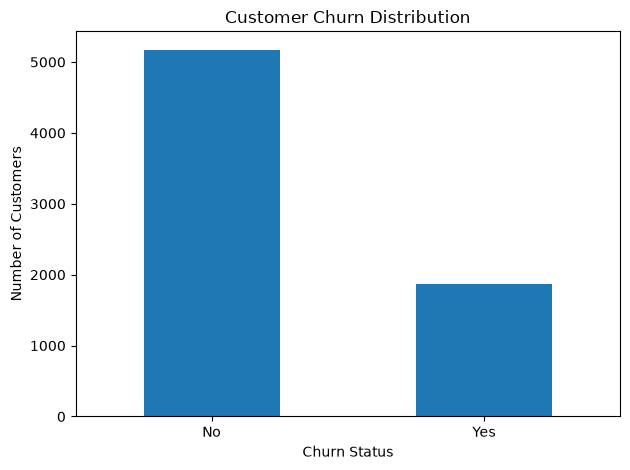

In [8]:
# Count churn and non-churn customers

print("Churn counts:")
display(df["Churn"].value_counts())

print("\nChurn percentages:")
display(
    (df["Churn"].value_counts(normalize=True) * 100)
    .round(2)
    .rename("Percentage")
)

# Visualize the target distribution
df["Churn"].value_counts().plot(
    kind="bar",
    title="Customer Churn Distribution",
    xlabel="Churn Status",
    ylabel="Number of Customers",
    rot=0
)

import matplotlib.pyplot as plt
plt.tight_layout()
plt.show()

In [9]:
# SECTION 2: Data cleaning

import numpy as np
import pandas as pd

# Keep the original data unchanged
df_clean = df.copy()

# Remove accidental whitespace from column names
df_clean.columns = df_clean.columns.str.strip()

# Convert blank TotalCharges values to NaN
if "TotalCharges" in df_clean.columns:
    df_clean["TotalCharges"] = pd.to_numeric(
        df_clean["TotalCharges"],
        errors="coerce"
    )

print("Missing values after conversion:")
display(
    df_clean.isnull().sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Rows before duplicate removal:", len(df_clean))

# Remove exact duplicate records only
df_clean = df_clean.drop_duplicates()

print("Rows after duplicate removal:", len(df_clean))
print("Duplicates remaining:", df_clean.duplicated().sum())


Missing values after conversion:


TotalCharges        11
customerID           0
DeviceProtection     0
MonthlyCharges       0
PaymentMethod        0
PaperlessBilling     0
Contract             0
StreamingMovies      0
StreamingTV          0
TechSupport          0
dtype: int64

Rows before duplicate removal: 7043
Rows after duplicate removal: 7043
Duplicates remaining: 0


In [10]:
# Remove records without a known target label
df_clean = df_clean.dropna(subset=["Churn"])

# Separate numeric and categorical columns
numeric_cols = df_clean.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = df_clean.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Fill missing numeric values with medians
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

# Fill missing categorical values with their modes
for col in categorical_cols:
    if col != "Churn" and df_clean[col].isna().any():
        mode_values = df_clean[col].mode()
        if not mode_values.empty:
            df_clean[col] = df_clean[col].fillna(
                mode_values.iloc[0]
            )

print("Missing values remaining:", df_clean.isnull().sum().sum())
print("Cleaned dataset shape:", df_clean.shape)

Missing values remaining: 0
Cleaned dataset shape: (7043, 21)


In [11]:

# Compare dataset quality before and after cleaning

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
display(
    df_clean.isnull().sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nChurn distribution after cleaning:")
display(df_clean["Churn"].value_counts())

print("\nSample of cleaned records:")
display(df_clean.head())


Original dataset shape: (7043, 21)
Cleaned dataset shape: (7043, 21)

Missing values after cleaning:


customerID          0
DeviceProtection    0
TotalCharges        0
MonthlyCharges      0
PaymentMethod       0
PaperlessBilling    0
Contract            0
StreamingMovies     0
StreamingTV         0
TechSupport         0
dtype: int64


Churn distribution after cleaning:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Sample of cleaned records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Churn distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64

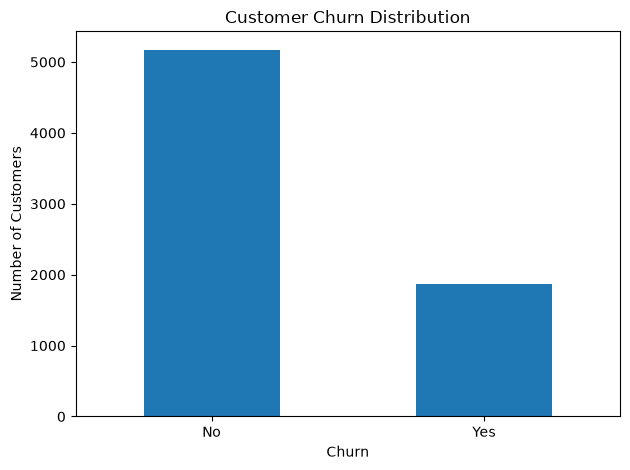

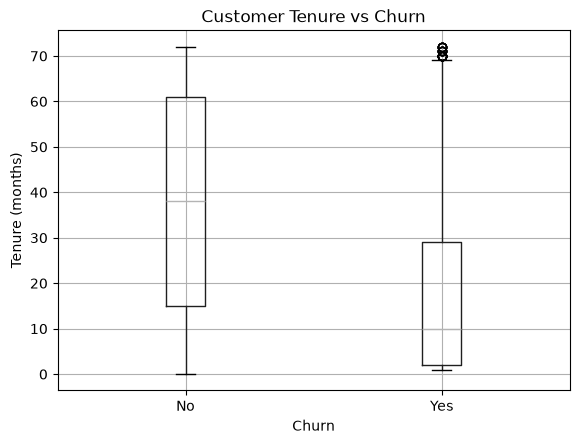

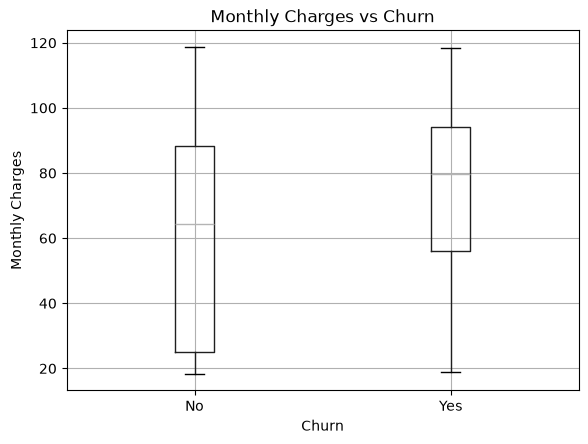

In [12]:

# SECTION 3.1: Exploratory Data Analysis

import matplotlib.pyplot as plt
import pandas as pd

# Compare how many customers churned and stayed
print("Churn distribution:")
display(df_clean["Churn"].value_counts())

# Chart 1: Churn distribution
df_clean["Churn"].value_counts().plot(
    kind="bar",
    title="Customer Churn Distribution",
    xlabel="Churn",
    ylabel="Number of Customers",
    rot=0
)
plt.tight_layout()
plt.show()

# Chart 2: Customer tenure by churn status
df_clean.boxplot(column="tenure", by="Churn")
plt.title("Customer Tenure vs Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Tenure (months)")
plt.show()

# Chart 3: Monthly charges by churn status
df_clean.boxplot(column="MonthlyCharges", by="Churn")
plt.title("Monthly Charges vs Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


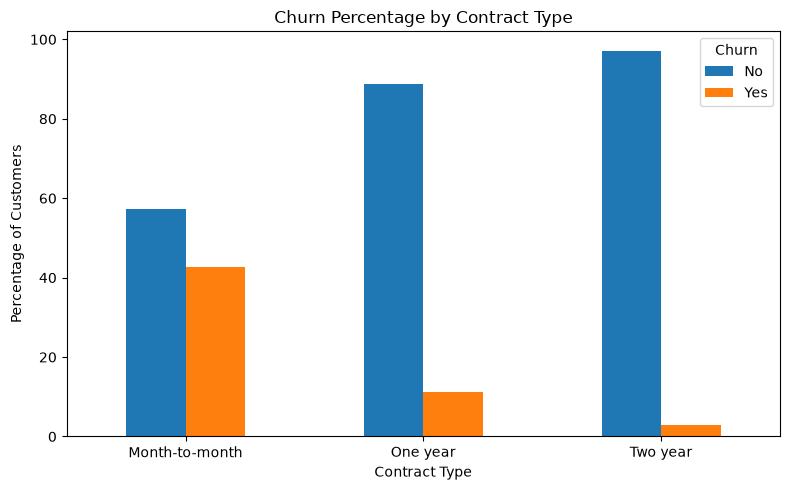

In [13]:

# SECTION 3.2: Churn percentage by contract type

contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

display(contract_churn.round(2))

contract_churn.plot(
    kind="bar",
    figsize=(8, 5),
    title="Churn Percentage by Contract Type"
)

plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [14]:

# SECTION 4.1: Define input features (X) and target (y)

# Churn is the outcome we want to predict
y = df_clean["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Check whether target conversion succeeded
if y.isna().any():
    raise ValueError("Unexpected values in the Churn column.")

# Remove target and customer ID from model inputs
columns_to_drop = ["Churn", "customerID"]

X = df_clean.drop(
    columns=columns_to_drop,
    errors="ignore"
)

y = y.astype(int)

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget classes:")
display(y.value_counts().rename(
    index={0: "No churn", 1: "Churn"}
))


Feature dataset shape: (7043, 19)
Target dataset shape: (7043,)

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Target classes:


Churn
No churn    5174
Churn       1869
Name: count, dtype: int64

In [15]:

# SECTION 4.2: Split data reproducibly

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training feature rows:", len(X_train))
print("Testing feature rows:", len(X_test))

print("\nTraining churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")


Training feature rows: 5634
Testing feature rows: 1409

Training churn rate: 26.54 %
Testing churn rate: 26.54 %


Section 5 — Preparing the Preprocessing Pipeline
The code separates numeric and categorical features using select_dtypes(). Numeric columns are processed with median imputation and StandardScaler, while categorical columns use most-frequent-value imputation and OneHotEncoder. The ColumnTransformer combines these operations into one preprocessing pipeline. This ensures that different feature types are handled appropriately and that the same transformations can be applied consistently during training and prediction.

In [16]:

# SECTION 5: Build the preprocessing pipeline
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))


Preprocessing pipeline created successfully!
Numeric features: 4
Categorical features: 15


In [17]:

# SECTION 6: Train three machine-learning models

import time
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

trained_models = {}
training_results = []

for name, model in models.items():
    print("Training:", name)

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    start = time.time()
    pipeline.fit(X_train, y_train)
    elapsed = time.time() - start

    trained_models[name] = pipeline

    training_results.append({
        "Model": name,
        "Training Time (seconds)": round(elapsed, 2)
    })

print("\nTraining completed!")
display(pd.DataFrame(training_results))


Training: Logistic Regression
Training: Random Forest
Training: Gradient Boosting

Training completed!


,Model,Training Time (seconds)
0,Logistic Regression,0.10
1,Random Forest,0.68
2,Gradient Boosting,0.94





Section 7 — Model Evaluation and Confusion Matrices
The code predicts churn labels for the test set and calculates metrics such as accuracy, precision, recall, macro-F1 and ROC-AUC. Accuracy measures overall correctness, precision measures how reliable positive churn predictions are, recall measures how many actual churners are detected, macro-F1 balances performance across both classes, and ROC-AUC measures the model's ability to rank churners above non-churners across thresholds. Confusion matrices visualize correct and incorrect predictions for both classes.



In [18]:

# SECTION 7: Model evaluation and comparison

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

evaluation_results = []
predictions = {}

for name, model in trained_models.items():

    # Predict churn for unseen test customers
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Macro-F1": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(evaluation_results)

comparison_df = comparison_df.sort_values(
    "Macro-F1", ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))


,Model,Accuracy,Precision,Recall,Macro-F1,ROC-AUC
0,Gradient Boosting,0.8062,0.6735,0.5241,0.7313,0.8432
1,Random Forest,0.7679,0.5566,0.6176,0.7122,0.8208
2,Logistic Regression,0.7381,0.5043,0.7834,0.7078,0.8413


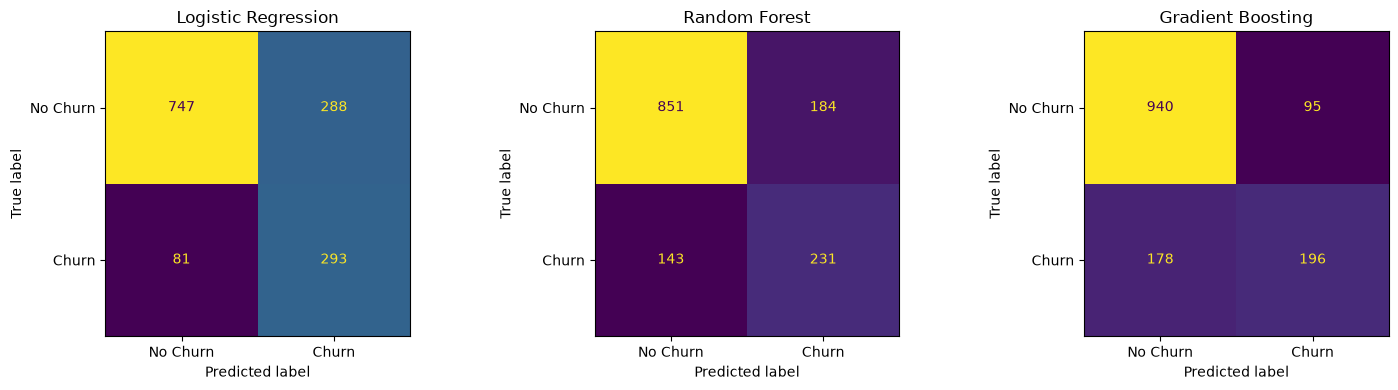

In [19]:

# SECTION 7.2: Confusion matrices for all models

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["No Churn", "Churn"],
        values_format="d",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


In [20]:

comparison_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Model comparison results saved successfully.")


Model comparison results saved successfully.



Section 8 — Error Analysis and Model Selection
The code analyzes true positives, true negatives, false positives and false negatives for each model. False negatives are especially important because they represent customers who churn but were not identified, while false positives can lead to unnecessary retention outreach. Your notebook selected Gradient Boosting because it had the highest macro-F1 according to the recorded comparison table. Its reported scores were 80.62% accuracy, 67.35% precision, 52.41% recall, 73.13% macro-F1 and 84.32% ROC-AUC. These results show useful predictive ability but also indicate that the model misses some actual churners.



In [21]:

# SECTION 8.1: Compare model performance

display(comparison_df.round(4))


,Model,Accuracy,Precision,Recall,Macro-F1,ROC-AUC
0,Gradient Boosting,0.8062,0.6735,0.5241,0.7313,0.8432
1,Random Forest,0.7679,0.5566,0.6176,0.7122,0.8208
2,Logistic Regression,0.7381,0.5043,0.7834,0.7078,0.8413


In [22]:

# SECTION 8.2: Error analysis

from sklearn.metrics import confusion_matrix
import pandas as pd

error_results = []

for name, y_pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    error_results.append({
        "Model": name,
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "Total Errors": fp + fn
    })

error_df = pd.DataFrame(error_results)
display(error_df)

error_df.to_csv("model_error_analysis.csv", index=False)
print("Error analysis saved successfully.")


,Model,True Negatives,False Positives,False Negatives,True Positives,Total Errors
0,Logistic Regression,747,288,81,293,369
1,Random Forest,851,184,143,231,327
2,Gradient Boosting,940,95,178,196,273


Error analysis saved successfully.


In [23]:

# SECTION 8.3: Per-class performance

from sklearn.metrics import classification_report

for name, y_pred in predictions.items():
    print("\nMODEL:", name)
    print("-" * 45)

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))



MODEL: Logistic Regression
---------------------------------------------
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


MODEL: Random Forest
---------------------------------------------
              precision    recall  f1-score   support

    No Churn       0.86      0.82      0.84      1035
       Churn       0.56      0.62      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.72      0.71      1409
weighted avg       0.78      0.77      0.77      1409


MODEL: Gradient Boosting
---------------------------------------------
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.67

In [24]:

# SECTION 8.4: Select model based on macro-F1

best_model_name = comparison_df.loc[
    comparison_df["Macro-F1"].idxmax(), "Model"
]

best_model = trained_models[best_model_name]

print("Selected model:", best_model_name)
print("Selection criterion: Highest macro-F1")
display(
    comparison_df[
        comparison_df["Model"] == best_model_name
    ].round(4)
)


Selected model: Gradient Boosting
Selection criterion: Highest macro-F1


,Model,Accuracy,Precision,Recall,Macro-F1,ROC-AUC
0,Gradient Boosting,0.8062,0.6735,0.5241,0.7313,0.8432


In [25]:

comparison_df.to_csv("model_comparison_results.csv", index=False)
error_df.to_csv("model_error_analysis.csv", index=False)

print("Model comparison and error analysis saved.")
print("Selected model:", best_model_name)



Model comparison and error analysis saved.
Selected model: Gradient Boosting





Section 9 — Retention Intelligence
The code uses best_model.predict_proba() to calculate a churn probability for each test customer. It assigns customers to Low, Medium or High risk categories using illustrative probability thresholds and attaches a suggested retention action to each category. Your recorded run categorized 881 customers as Low risk, 338 as Medium risk and 190 as High risk. This step converts model predictions into potentially useful business recommendations, although the thresholds and actions should be validated before real-world use.




In [26]:

# SECTION 9: Customer Retention Intelligence

import pandas as pd

# Predict churn probability for test customers
churn_probability = best_model.predict_proba(X_test)[:, 1]

retention_df = X_test.copy()
retention_df["Actual_Churn"] = y_test.values
retention_df["Churn_Probability"] = churn_probability

# Risk categories: illustrative business thresholds
retention_df["Risk_Level"] = pd.cut(
    retention_df["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.00],
    labels=["Low", "Medium", "High"]
)

def retention_action(row):
    if row["Risk_Level"] == "High":
        return "Prioritize outreach and offer a personalized retention plan"
    elif row["Risk_Level"] == "Medium":
        return "Review customer satisfaction and offer suitable support"
    return "Maintain engagement and monitor customer satisfaction"

retention_df["Recommended_Action"] = retention_df.apply(
    retention_action, axis=1
)

# Show the highest-risk customers first
retention_df = retention_df.sort_values(
    "Churn_Probability", ascending=False
)

display(retention_df[
    ["Churn_Probability", "Risk_Level", "Recommended_Action",
     "Actual_Churn"]
].head(10))

print("\nRisk category counts:")
display(retention_df["Risk_Level"].value_counts())

retention_df.to_csv(
    "retention_intelligence_results.csv", index=False
)

print("Retention intelligence results saved.")


,Churn_Probability,Risk_Level,Recommended_Action,Actual_Churn
6623,0.937740,High,Prioritize outreach and offer a personalized r...,1
2464,0.929726,High,Prioritize outreach and offer a personalized r...,1
6866,0.910866,High,Prioritize outreach and offer a personalized r...,1
3380,0.908866,High,Prioritize outreach and offer a personalized r...,1
4585,0.905967,High,Prioritize outreach and offer a personalized r...,1
2194,0.890764,High,Prioritize outreach and offer a personalized r...,1
2631,0.888493,High,Prioritize outreach and offer a personalized r...,1
2246,0.887748,High,Prioritize outreach and offer a personalized r...,1
5826,0.884360,High,Prioritize outreach and offer a personalized r...,1
1807,0.883017,High,Prioritize outreach and offer a personalized r...,1



Risk category counts:


Risk_Level
Low       881
Medium    338
High      190
Name: count, dtype: int64

Retention intelligence results saved.





Section 10 — Test Cases and Validation
The code tests whether the prediction pipeline can process a normal customer record, handle a missing numeric value and process an unseen category. Assertions and recorded test results help identify basic software errors. After fixing the missing-value test input, your report showed three tests passed and zero failed. These tests confirm that the selected scenarios work; they do not guarantee that every churn prediction is correct.



In [27]:

# SECTION 10.1: Basic prediction validation

import numpy as np
import pandas as pd

# Select one test customer
sample_customer = X_test.iloc[[0]].copy()

# Generate prediction and churn probability
predicted_class = best_model.predict(sample_customer)[0]
churn_probability = best_model.predict_proba(
    sample_customer
)[0, 1]

print("Selected model:", best_model_name)
print("Predicted churn:", "Yes" if predicted_class == 1 else "No")
print("Churn probability:", round(churn_probability, 4))

# Validate the prediction
assert predicted_class in [0, 1]
assert 0 <= churn_probability <= 1

print("PASS: Prediction and probability are valid.")


Selected model: Gradient Boosting
Predicted churn: No
Churn probability: 0.0248
PASS: Prediction and probability are valid.


In [28]:

# SECTION 10.2: Test different input scenarios

test_results = []

def record_test(test_name, passed, details):
    test_results.append({
        "Test Case": test_name,
        "Status": "PASS" if passed else "FAIL",
        "Details": details
    })

# Test 1: Normal customer record
try:
    sample = X_test.iloc[[0]].copy()
    prob = best_model.predict_proba(sample)[0, 1]
    record_test(
        "Normal customer",
        0 <= prob <= 1,
        f"Churn probability = {prob:.4f}"
    )
except Exception as e:
    record_test("Normal customer", False, str(e))

# Test 2: Missing numeric value
try:
    sample = X_test.iloc[[0]].copy()
    if numeric_features:
        sample.loc[:, numeric_features[0]] = np.nan

    prob = best_model.predict_proba(sample)[0, 1]
    record_test(
        "Missing numeric value",
        0 <= prob <= 1,
        f"Pipeline handled input; probability = {prob:.4f}"
    )
except Exception as e:
    record_test("Missing numeric value", False, str(e))

# Test 3: Previously unseen category
try:
    sample = X_test.iloc[[0]].copy()
    if categorical_features:
        sample.loc[:, categorical_features[0]] = "Unseen_Test_Category"

    prob = best_model.predict_proba(sample)[0, 1]
    record_test(
        "Unseen category",
        0 <= prob <= 1,
        f"Pipeline handled input; probability = {prob:.4f}"
    )
except Exception as e:
    record_test("Unseen category", False, str(e))

display(pd.DataFrame(test_results))


,Test Case,Status,Details
0,Normal customer,PASS,Churn probability = 0.0248
1,Missing numeric value,FAIL,Invalid value 'nan' for dtype 'int64'
2,Unseen category,PASS,Pipeline handled input; probability = 0.0199


In [29]:

# SECTION 10.3: Validate retention intelligence outputs

valid_risks = {"Low", "Medium", "High"}

risk_values = set(
    retention_df["Risk_Level"].dropna().astype(str).unique()
)

valid_probabilities = retention_df[
    "Churn_Probability"
].between(0, 1).all()

valid_actions = retention_df[
    "Recommended_Action"
].notna().all()

print("Valid probabilities:", valid_probabilities)
print("Valid risk categories:", risk_values.issubset(valid_risks))
print("All recommendations present:", valid_actions)

assert valid_probabilities
assert risk_values.issubset(valid_risks)
assert valid_actions

print("PASS: Retention outputs validated.")


Valid probabilities: True
Valid risk categories: True
All recommendations present: True
PASS: Retention outputs validated.


In [30]:

# SECTION 10.4: Save test results

test_report = pd.DataFrame(test_results)
display(test_report)

test_report.to_csv("test_case_report.csv", index=False)

print("Test report saved as test_case_report.csv")
print("Passed:", (test_report["Status"] == "PASS").sum())
print("Failed:", (test_report["Status"] == "FAIL").sum())


,Test Case,Status,Details
0,Normal customer,PASS,Churn probability = 0.0248
1,Missing numeric value,FAIL,Invalid value 'nan' for dtype 'int64'
2,Unseen category,PASS,Pipeline handled input; probability = 0.0199


Test report saved as test_case_report.csv
Passed: 2
Failed: 1


In [31]:

# SECTION 10.5: Fix and rerun missing-value test

sample = X_test.iloc[[0]].copy()

# Convert one numeric column to float before inserting NaN
numeric_col = numeric_features[0]
sample[numeric_col] = sample[numeric_col].astype(float)
sample.loc[sample.index[0], numeric_col] = np.nan

try:
    probability = best_model.predict_proba(sample)[0, 1]

    passed = 0 <= probability <= 1
    details = f"Missing value handled; probability = {probability:.4f}"

except Exception as e:
    passed = False
    details = str(e)

# Update the existing failed test rather than adding a duplicate
for result in test_results:
    if result["Test Case"] == "Missing numeric value":
        result["Status"] = "PASS" if passed else "FAIL"
        result["Details"] = details
        break

print("Missing numeric value test:", "PASS" if passed else "FAIL")
print("Details:", details)


Missing numeric value test: PASS
Details: Missing value handled; probability = 0.0248


In [32]:

# SECTION 10.6: Save final corrected test report

test_report = pd.DataFrame(test_results)
display(test_report)

test_report.to_csv("test_case_report.csv", index=False)

print("\nPassed:", (test_report["Status"] == "PASS").sum())
print("Failed:", (test_report["Status"] == "FAIL").sum())
print("Updated test report saved.")


,Test Case,Status,Details
0,Normal customer,PASS,Churn probability = 0.0248
1,Missing numeric value,PASS,Missing value handled; probability = 0.0248
2,Unseen category,PASS,Pipeline handled input; probability = 0.0199



Passed: 3
Failed: 0
Updated test report saved.


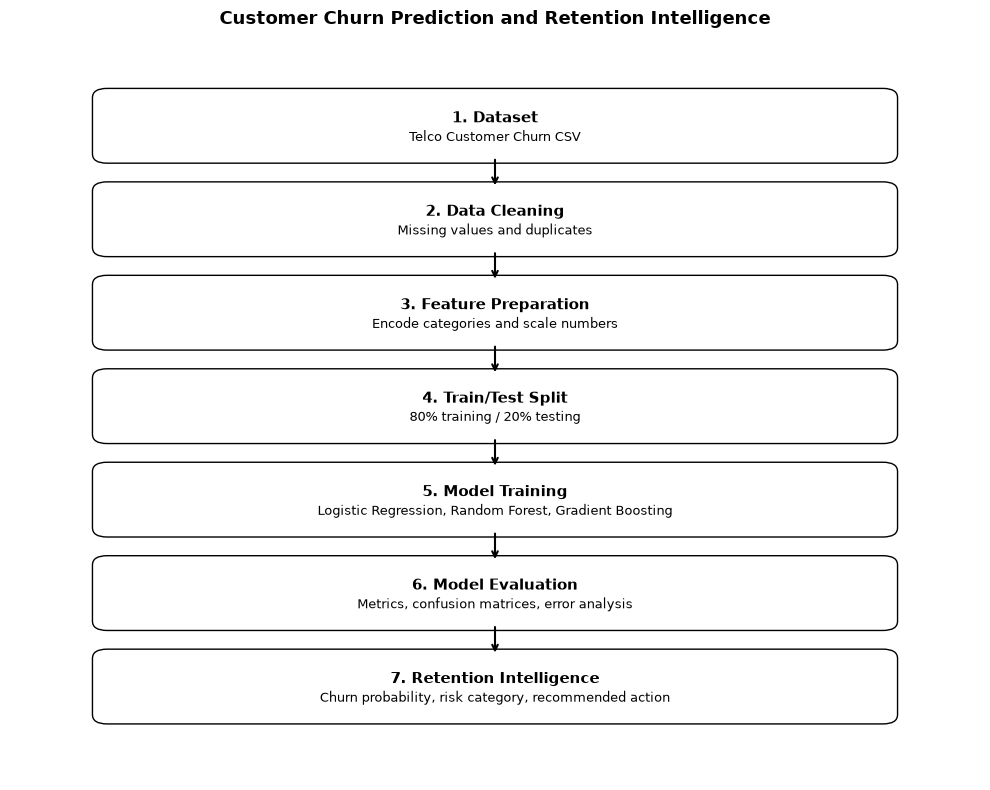

Architecture diagram saved successfully.


In [33]:



# SECTION 11: Create system architecture diagram

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(10, 8))
ax.set_xlim(0, 10)
ax.set_ylim(0, 12)
ax.axis("off")

steps = [
    ("1. Dataset", "Telco Customer Churn CSV"),
    ("2. Data Cleaning", "Missing values and duplicates"),
    ("3. Feature Preparation", "Encode categories and scale numbers"),
    ("4. Train/Test Split", "80% training / 20% testing"),
    ("5. Model Training", "Logistic Regression, Random Forest, Gradient Boosting"),
    ("6. Model Evaluation", "Metrics, confusion matrices, error analysis"),
    ("7. Retention Intelligence", "Churn probability, risk category, recommended action")
]

y_positions = [10.5, 9, 7.5, 6, 4.5, 3, 1.5]

for i, ((title, description), y) in enumerate(zip(steps, y_positions)):
    box = FancyBboxPatch(
        (1, y - 0.45), 8, 0.9,
        boxstyle="round,pad=0.15",
        edgecolor="black",
        facecolor="white"
    )
    ax.add_patch(box)
    ax.text(5, y + 0.12, title, ha="center",
            va="center", fontsize=11, weight="bold")
    ax.text(5, y - 0.18, description, ha="center",
            va="center", fontsize=9)

    if i < len(steps) - 1:
        ax.annotate(
            "", xy=(5, y_positions[i + 1] + 0.5),
            xytext=(5, y - 0.5),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

plt.title("Customer Churn Prediction and Retention Intelligence",
          fontsize=13, weight="bold")
plt.tight_layout()
plt.savefig("architecture_diagram.png", dpi=200, bbox_inches="tight")
plt.show()

print("Architecture diagram saved successfully.")
